In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [3]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

Log-rank test: chi-squared statistic of 0.11102525773640061 (p=0.7389799001044497)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading UCSF maps:   0%|          | 0/367 [00:00<?, ?it/s]

Loading UCSF maps: 100%|██████████| 367/367 [00:07<00:00, 49.34it/s]


In [4]:
# from utils import unflatten_maps


# nifti_obj = unflatten_maps(
#     TD_maps=maps_ucsf, 
#     template=T1_file, 
#     return_nifti=True
# )

# nib.save(nifti_obj, 'loading_maps_result.nii.gz')

# from nilearn import image


# nifti_img_4d = unflatten_maps(maps_ucsf, T1_file, return_nifti=True)

# nifti_img_3d = image.index_img(nifti_img_4d, 0)

# plotting.plot_glass_brain(nifti_img_3d, colorbar=True, display_mode='lyrz', black_bg=True, title='Statistical Map')

# from nilearn import plotting


# nifti_img_3d = image.index_img(nifti_img_4d, 100)


# plotting.plot_stat_map(
#     nifti_img_3d, 
#     bg_img=T1_file, 
#     display_mode='z',
#     cut_coords=7,
#     threshold=0.3,
#     title="Axial Loading Map Series",
#     colorbar=True,
#     cmap='viridis'
# )

In [4]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:11<00:00, 44.74it/s]


In [9]:
from dataclasses import dataclass, field


@dataclass
class Dataset:
    name: str
    path: str
    maps: np.ndarray
    df: pd.DataFrame

    def __str__(self):
        return self.name.upper()
    
from typing import TypeAlias, Union
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA
from nmf import NMFProjections


Projector: TypeAlias = Union[TD_Kernel_PCA, TD_PCA, NMFProjections]

class Transformer:
    def __init__(self, projector: Projector):
        self.projector = projector

    def fit_transform(self, norm, **kwargs):
        return self.projector.fit_transform_maps(norm=norm, **kwargs)
    
    def transform(self, maps):
        return self.projector.transform_maps(maps)
# class Transformer:
#     def __init__(self, projector):
#         self.projector = projector
#         # self.is_fitted = False

#     def fit(self, norm, **kwargs):
#         self.projector.fit(norm=norm, **kwargs)
#         # self.is_fitted = True
#         return self

#     def transform(self, maps):
#         # if not self.is_fitted:
#             # raise RuntimeError("First call fit() or fit_transform()!")
#         return self.projector.transform_maps(maps)

#     def fit_transform(self, norm, **kwargs):
#         """Trenuje i od razu transformuje (dla zbioru treningowego)."""
#         # Możesz to zrobić elegancko, wywołując własne metody:
#         # self.fit(norm=norm, **kwargs)
#         # Zauważ, że fit w TD_VAE zazwyczaj używa self.training_maps, 
#         # więc transformujemy te same dane, na których się uczyliśmy.
#         return self.transform(self.projector.training_maps)
    
from lifelines import CoxPHFitter


class TD_CoxPHFitter:
    def __init__(self, penalizer: float | int = 0.01,):
        self.penalizer = penalizer
        self._cph = CoxPHFitter(penalizer=penalizer)
    
    def fit(self, X_train: pd.DataFrame, duration_col: str, event_col: str):
        self._cph.fit(X_train, duration_col, event_col=event_col)

    def score(self, X_test: pd.DataFrame, scoring_method: str = "log_likelihood"):
        return self._cph.score(X_test, scoring_method)
    
    def plot(self, ax):
        self._cph.plot(ax=ax)
    
    @property
    def concordance_index(self):
        if not hasattr(self._cph, "concordance_index_"):
            raise ValueError("CoxPHFitter not fitted yet. Fit it first")
        return self._cph.concordance_index_
    
    @property
    def cph(self):
        return self._cph
    
from dataclasses import dataclass
import matplotlib.pyplot as plt

@dataclass
class ModelConfig:
    penalizer: float = 0.01
    duration_col: str = 'OS (corrected)'
    event_col: str = 'status'
    n_components: int = 100

from enum import Enum

from pipeline_encoder import EncodingPipeline


class DataTransformer:
    class FeatureMethod(Enum):
        COSINE = "Cos"
        RBF = "RBF"
        PCA = "PCA"
        NMF = "NMF"

    COMPONENT_PREFIX = "Comp"
    COLUMNS_TO_DROP = ["volume", "site", "OS", "ID", "ltdi", "tdi"]
    NUMERICAL_COLUMNS_TO_DROP = ["OS (corrected)", "status"]

    @staticmethod
    def add_extracted_mapsdata(df_base: pd.DataFrame, extracted_features: np.ndarray, method: FeatureMethod, n_components: int, column_names: list[str] | None = None) -> pd.DataFrame:
        if column_names is None:
            column_names = [f"{method.value}_{DataTransformer.COMPONENT_PREFIX}_{i+1}" for i in range(n_components)]
        
        df_new_features = pd.DataFrame(
            extracted_features,
            columns=column_names, 
            index=df_base.index
        )

        df_all = pd.concat([df_base, df_new_features], axis=1)

        return df_all
    
    @staticmethod
    def drop_columns(df_base: pd.DataFrame):
        columns_to_drop = DataTransformer.COLUMNS_TO_DROP
        df_base = df_base.drop(columns=columns_to_drop)

        return df_base
    
    @staticmethod
    def feature_fit_transform(encoding_pipeline: EncodingPipeline):
        df_base = encoding_pipeline.df
        
        categorical_features = df_base.select_dtypes(include="object").columns
        numerical_features = df_base.select_dtypes(exclude="object").columns

        numerical_features = numerical_features.drop(DataTransformer.NUMERICAL_COLUMNS_TO_DROP)

        X_transformed = encoding_pipeline.fit_transform(list(numerical_features), list(categorical_features))

        return X_transformed
    

    @staticmethod
    def feature_transform(test_df: pd.DataFrame, encoding_pipeline: EncodingPipeline):
        X_transformed = encoding_pipeline.transform(test_df)
        
        return X_transformed


## Datasets

In [7]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
# dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!
upenn training Concordance Index: 0.6881
ucsf testing Concordance Index: 0.6131


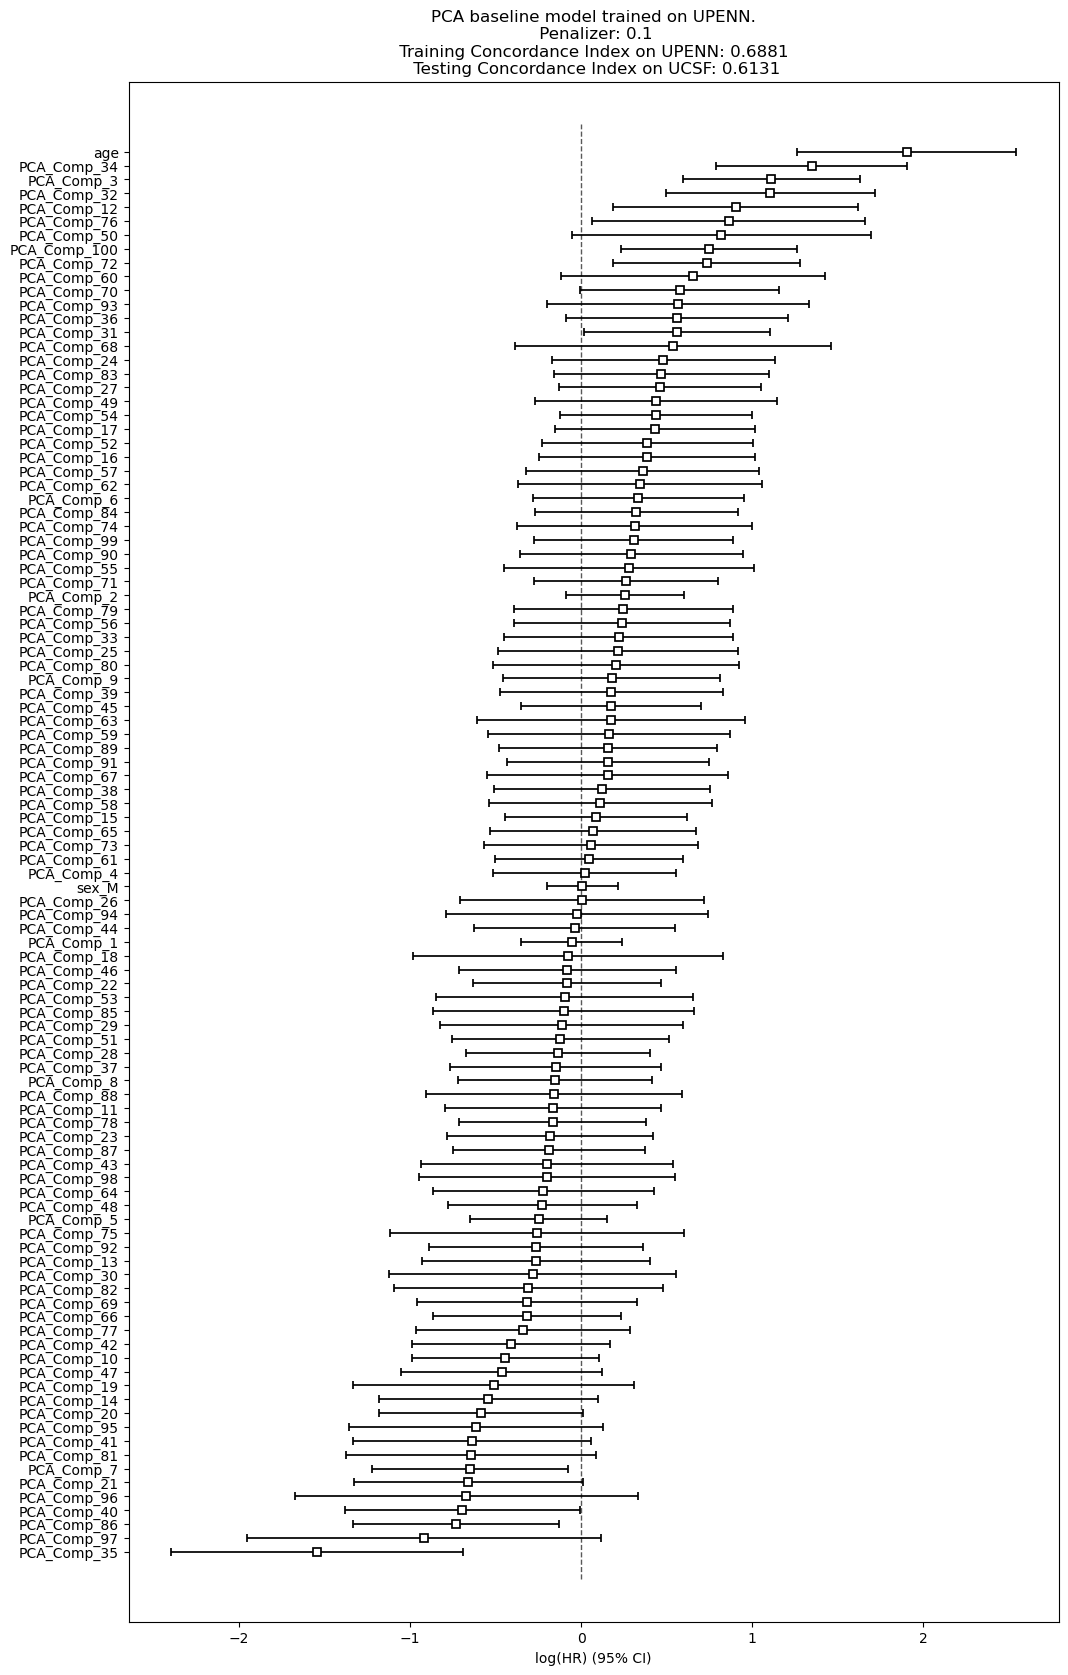

In [ ]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections

import sklearn

normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)

df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

# method = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
method = TD_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components)
# method = NMFProjections(training_maps, template=T1, binary_mask=T1_brain, n_components=n_components, max_iter=10)
trainer = Transformer(method)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_base = df_training

X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
df_base = DataTransformer.drop_columns(X_train_with_features)
encoding_pipeline = EncodingPipeline(df_base)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"{method} baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)